# 3. Avaliação e exportação

Mede o modelo final (`notavelai`) do mesmo jeito que o app, em fotos que ele nunca viu no treino:
metade do teste do Kaggle, o conjunto extra dos autores do Kaggle e as fotos de celular do grupo.

In [1]:
import csv
import os
import sys
import warnings
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

# Permite importar src/ com o notebook aberto a partir de notebooks/ ou da raiz.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import matplotlib.pyplot as plt
import numpy as np

from src.data.dataset import CLASSES, PROCESSED_DIR, print_table
from src.models import ensemble, evaluate
from src.models.predict import expand, load

# train_model escolhe o backend Agg ao ser importado; aqui as figuras precisam aparecer.
%matplotlib inline

# True recria os .tflite e o labels.txt em models/ a partir dos .keras.
EXPORTAR = False

## Exportação

O modelo vira um `.tflite` float32 de 8,9 MB. O int8 foi testado numa versão anterior e descartado:
errava mais que o float32.

In [2]:
if EXPORTAR:
    ensemble.export()
for path in ensemble.tflite_paths():
    print(f"{path.name}: {path.stat().st_size / 1e6:.1f} MB")

notavelai.tflite: 8.9 MB


In [3]:
evaluate.main()

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


notavelai.tflite: 0 previsões diferentes do Keras
{'model': 'notavelai', 'validation_correct': '200/204', 'validation_spoken_right': 182, 'validation_spoken_wrong': 2, 'phone_correct': '19/24', 'phone_spoken_right': 18, 'phone_spoken_wrong': 0, 'kaggle_correct': '129/135', 'kaggle_spoken_right': 127, 'kaggle_spoken_wrong': 2, 'kaggle_extra_correct': '62/66', 'kaggle_extra_spoken_right': 59, 'kaggle_extra_spoken_wrong': 3}
Modelo final: 8.9 MB, 2.1 ms por foto (1 thread, neste computador)


## Resultados

"Fala certo" e "fala errado" contam as vezes em que o app anunciaria um valor: confiança de pelo
menos 70% e classe diferente de `fundo`. Para quem não enxerga a nota, falar um valor errado é o
pior erro. Abaixo, as fotos de celular do grupo em que a classe mais provável não é a certa.

In [4]:
with evaluate.SUMMARY_PATH.open(encoding="utf-8") as file:
    rows = list(csv.reader(file))
print_table(rows[1:], rows[0])

with evaluate.PHOTOS_PATH.open(encoding="utf-8") as file:
    errors = [[r["file"], r["true_label"], r["predicted"], r["confidence"], r["app_says"]]
              for r in csv.DictReader(file) if r["true_label"] != r["predicted"]]
print_table(errors, ["arquivo", "real", "previsto", "confiança", "app fala"])

    model  validation_correct  validation_spoken_right  validation_spoken_wrong  phone_correct  phone_spoken_right  phone_spoken_wrong  kaggle_correct  kaggle_spoken_right  kaggle_spoken_wrong  kaggle_extra_correct  kaggle_extra_spoken_right  kaggle_extra_spoken_wrong
---------  ------------------  -----------------------  -----------------------  -------------  ------------------  ------------------  --------------  -------------------  -------------------  --------------------  -------------------------  -------------------------
notavelai             200/204                      182                        2          19/24                  18                   0         129/135                  127                    2                 62/66                         59                          3
                arquivo   real  previsto  confiança        app fala
-----------------------  -----  --------  ---------  --------------
IMG_20261029_145543.jpg    200     fundo      0.867     n

## Exemplo de inferência

Faz o mesmo caminho do app: quadrado central da foto reduzido a 224x224, valores 0–255 sem
normalizar e a classe lida de `labels.txt`. Mostra uma cédula da validação por classe.

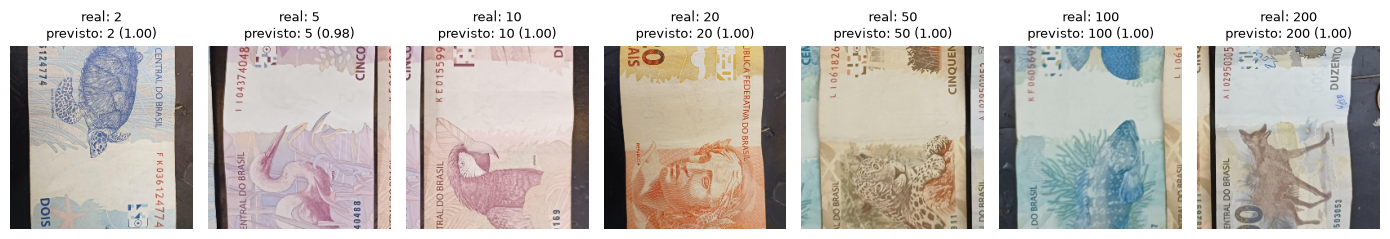

In [5]:
labels = ensemble.LABELS_PATH.read_text(encoding="utf-8").splitlines()
files = expand([PROCESSED_DIR / "valid"])
chosen = [next(f for f in files if f.parent.name == label) for label in CLASSES]
images = np.stack([load(f) for f in chosen])
probabilities = ensemble.predict(images)

figure, axes = plt.subplots(1, len(chosen), figsize=(14, 2.6))
for axis, file, image, scores in zip(axes, chosen, images, probabilities):
    axis.imshow(image.astype("uint8"))
    axis.set_title(f"real: {file.parent.name}\nprevisto: {labels[int(np.argmax(scores))]} ({scores.max():.2f})", fontsize=9)
    axis.axis("off")
figure.tight_layout()
plt.show()

## Limitações

- **Primeira família:** as notas antigas quase não estão no treino; a R$ 100 e a R$ 10 antigas
  falharam com frequência nos testes do grupo.
- **R$ 5 e R$ 10** são a confusão mais comum.
- **Enquadramento:** o modelo olha o quadrado central; nota pequena e longe do centro pode sair
  como `fundo` (2 das 5 fotos de R$ 200 do grupo).
- **Teste do grupo pequeno:** só 24 fotos, e elas também orientaram escolhas do projeto.
- **Não substitui a conferência:** é um protótipo e não deve ser a única forma de conferir dinheiro.